# Équité et explicabilité — validation de développement
Repondération estimée sur le train ; seuil global sélectionné sur validation sous contraintes DI >= 0.8, écart TPR <= 0.10, recall >= 0.50 et acceptation entre 0.10 et 0.95. Les comparateurs utilisent les intersections genre/âge.
ThresholdOptimizer demande des attributs sensibles à la décision et randomise ses sorties : comparateur d'étude uniquement, avec limite juridique potentielle exposée dans la Model Card. ExponentiatedGradient utilise une mixture randomisée. Le biais est mesuré et contrôlé selon les métriques affichées sur ce split ; aucune absence générale de biais n'est affirmée.
Le candidat respecte la validation de phase 5, mais son AUC reste sous 0.74 : il n'est pas promu. Le test indépendant et la supervision restent nécessaires.

In [1]:
import json
import pickle
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd() if Path("params.yaml").exists() else Path.cwd().parent
assert Path(sys.prefix).resolve() == (ROOT / "creditS").resolve()
comparison = json.loads(
    (ROOT / "reports/fairness/mitigation_comparison.json").read_text(encoding="utf-8")
)
audits = json.loads((ROOT / "reports/fairness/fairness_report.json").read_text(encoding="utf-8"))
rows = pd.DataFrame(comparison["results"])
selected = comparison["selected_group_free_candidate"]
print("Candidate:", selected)
print("Positive = default/refusal; selection = acceptance = 1 - prediction.")
print("Comparisons: known gender F/M and age groups with sufficient support; test reserved.")

Candidate: reweighing_1.5
Positive = default/refusal; selection = acceptance = 1 - prediction.
Comparisons: known gender F/M and age groups with sufficient support; test reserved.


In [2]:
columns = [
    "method",
    "validation_auc",
    "validation_decision_auc",
    "validation_recall",
    "threshold",
    "CODE_GENDER_disparate_impact",
    "CODE_GENDER_equal_opportunity_difference",
    "AGE_GROUP_disparate_impact",
    "AGE_GROUP_equal_opportunity_difference",
    "passes_phase5",
]
print(rows[columns].round(4).to_string(index=False))
best = rows.loc[rows.method == selected].iloc[0]
print("AUC loss in percentage points:", round(100 * best.auc_loss_vs_baseline, 4))
print("Future quality gate minimum AUC 0.74 still fails:", best.validation_auc < 0.74)
print("TO ranks base scores; EG ranks mixture refusal probabilities.")

                method  validation_auc  validation_decision_auc  validation_recall  threshold  CODE_GENDER_disparate_impact  CODE_GENDER_equal_opportunity_difference  AGE_GROUP_disparate_impact  AGE_GROUP_equal_opportunity_difference  passes_phase5
              baseline          0.7487                   0.6840             0.6146       0.49                        0.8901                                    0.0722                      0.5996                                  0.1974          False
        reweighing_0.5          0.7427                   0.6800             0.5491       0.54                        0.9370                                    0.0812                      0.7178                                  0.1700          False
          reweighing_1          0.7374                   0.6674             0.5164       0.55                        0.9676                                    0.0340                      0.7602                                  0.1690          False
    

In [3]:
for name in ("baseline", selected):
    print()
    print("Method:", name)
    for attribute, report in audits[name]["attributes"].items():
        print("Attribute:", attribute, "coverage:", report["comparison_coverage"])
        print(pd.DataFrame(report["by_group"]).T.to_string())
print("XNA is displayed but not certified. Undefined TPR is null, not zero.")
print("Small default counts imply uncertain TPR gaps; validation selection can be optimistic.")


Method: baseline
Attribute: AGE_GROUP coverage: 1.0
      acceptance_rate       auc comparison_eligible default_rate defaults       fpr non_defaults refusal_rate  rows       tpr
30-45        0.702328  0.750706                True     0.099059      200  0.261682         1819     0.297672  2019     0.625
45-60        0.799514  0.748875                True     0.057716       95  0.178594         1551     0.200486  1646  0.557895
60+          0.853704  0.715953                True     0.048148       26  0.128405          514     0.146296   540       0.5
<30          0.511888    0.6936                True     0.106294       76  0.463224          639     0.488112   715  0.697368
Attribute: CODE_GENDER coverage: 0.9997967479674796
    acceptance_rate       auc comparison_eligible default_rate defaults       fpr non_defaults refusal_rate  rows       tpr
F           0.75185  0.746208                True     0.071208      231   0.22237         3013      0.24815  3244  0.584416
M          0.6692

In [4]:
proxy = json.loads((ROOT / "reports/fairness/proxy_report.json").read_text(encoding="utf-8"))
print("Gender proxy validation AUC:", round(proxy["validation_gender_auc"], 4))
print(pd.DataFrame(proxy["top_features"]).head(10).round(4).to_string(index=False))
print("Associations and predictive proxies do not establish causality.")

Gender proxy validation AUC: 0.8734
                       feature  standardized_coefficient  train_gender_correlation
       OCCUPATION_TYPE_Drivers                    0.7898                    0.3239
       NONLIVINGAPARTMENTS_AVG                    0.6438                    0.0073
      NONLIVINGAPARTMENTS_MEDI                   -0.6098                    0.0049
    INSTALLMENTS_PAYMENT_COUNT                   -0.5573                   -0.0570
            INSTALLMENTS_COUNT                    0.5021                   -0.0567
   OCCUPATION_TYPE_Accountants                   -0.4773                   -0.1121
                APARTMENTS_AVG                    0.4251                    0.0259
   OCCUPATION_TYPE_Sales staff                   -0.4228                   -0.1586
      OCCUPATION_TYPE_Laborers                    0.3903                    0.2187
OCCUPATION_TYPE_Medicine staff                   -0.3548                   -0.1123
Associations and predictive proxies do not establis

In [5]:
from src.models.explain import CreditExplainer

bundle = pickle.loads((ROOT / "artifacts/fairness_models/candidate.pkl").read_bytes())
x = pd.read_csv(ROOT / "data/processed/X_val.csv", index_col="SK_ID_CURR", nrows=1)
explainer = CreditExplainer(bundle)
print(json.dumps(explainer.top_reasons(x, k=3), indent=2, ensure_ascii=False))
report = json.loads((ROOT / "reports/shap/candidate/shap_report.json").read_text(encoding="utf-8"))
print("SHAP units:", report["units"])
print("Maximum probability reconstruction error:", report["max_probability_reconstruction_error"])
print("Explanations refer to model associations and transformed/imputed values.")

[
  {
    "feature": "EXT_SOURCE_MEAN",
    "label": "Moyenne des scores externes disponibles",
    "direction": "diminue le score de défaut",
    "contribution_raw_score": -0.33270583684937977,
    "transformed_value": 0.68351334,
    "interpretation": "association du modèle, pas une cause"
  },
  {
    "feature": "INSTALLMENTS_DELAY_MEAN",
    "label": "Retard moyen de paiement en jours",
    "direction": "augmente le score de défaut",
    "contribution_raw_score": 0.2737208723244335,
    "transformed_value": 2.4347825,
    "interpretation": "association du modèle, pas une cause"
  },
  {
    "feature": "DAYS_LAST_PHONE_CHANGE",
    "label": "Ancienneté du changement de téléphone (jours négatifs)",
    "direction": "diminue le score de défaut",
    "contribution_raw_score": -0.21703698232864946,
    "transformed_value": -2811.0,
    "interpretation": "association du modèle, pas une cause"
  }
]
SHAP units: raw log-odds of predicted default; positive increases default score
Maximum pr

Performance et écart TPR : la couleur tient aussi compte du DI, de la perte AUC et de l'utilité.
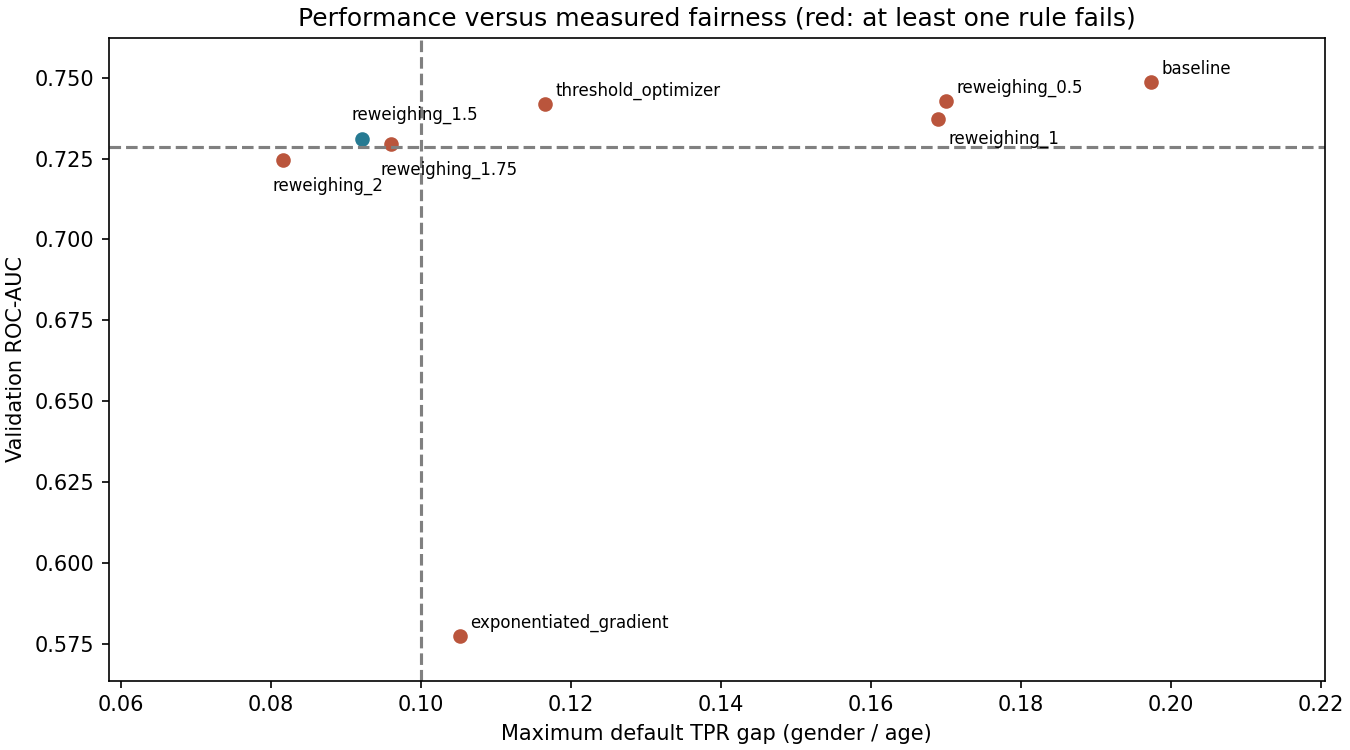

SHAP summary : une contribution positive augmente le score brut du défaut.
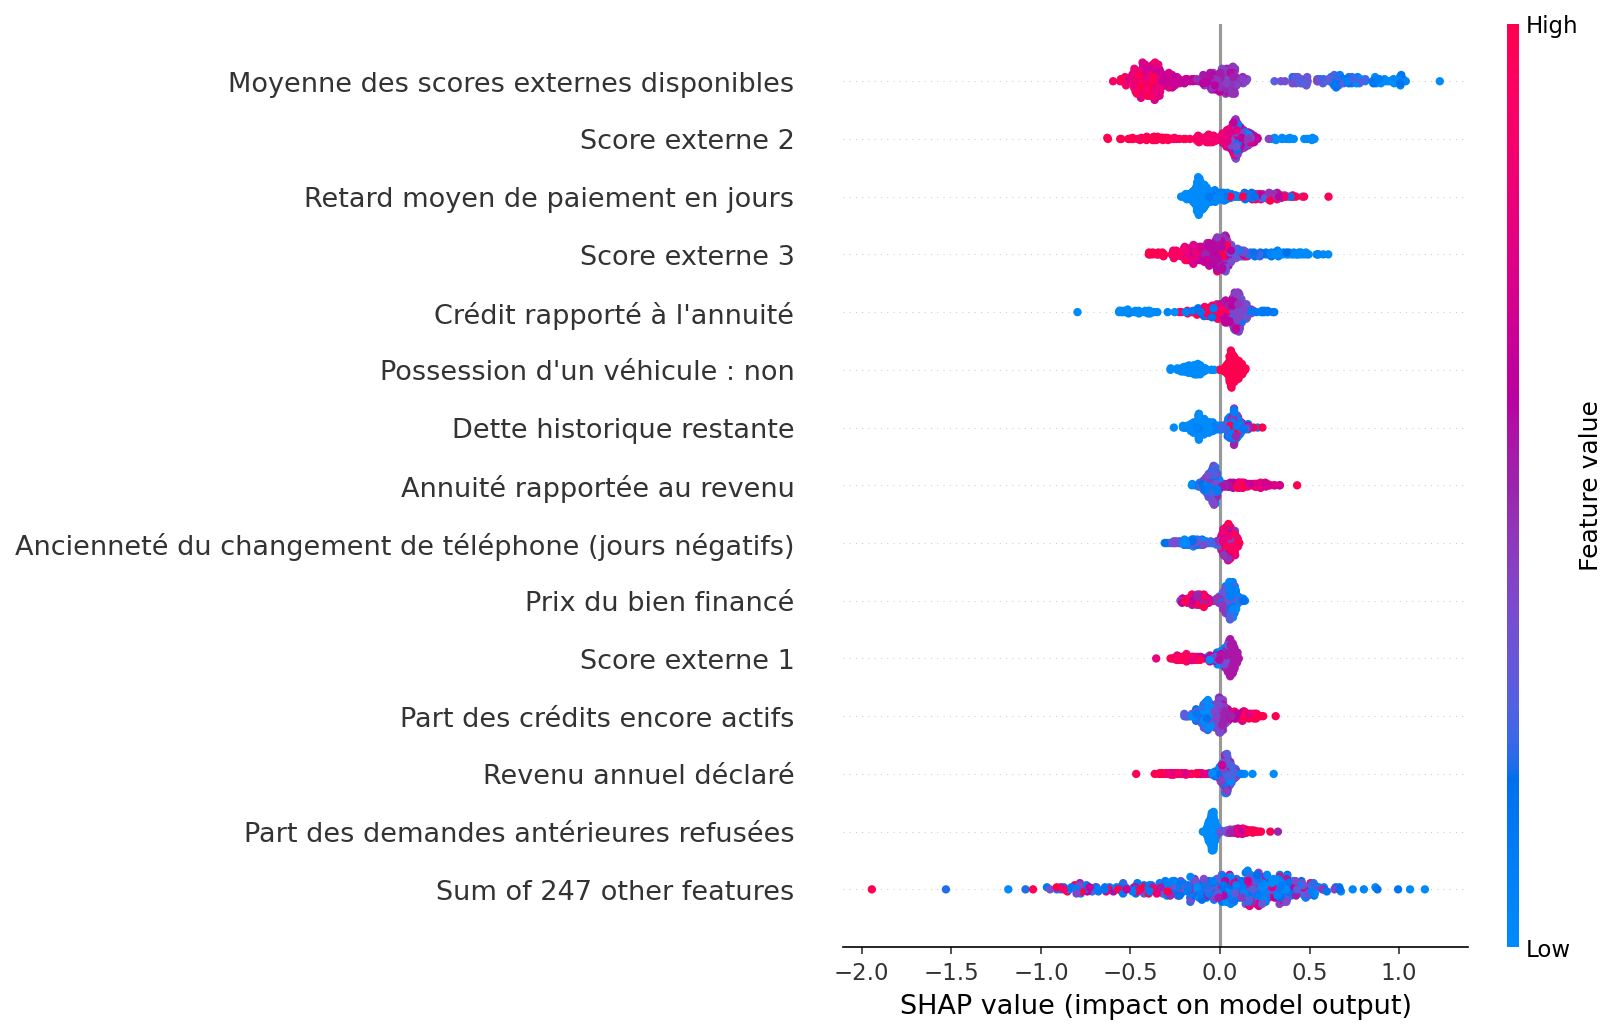

SHAP waterfall : cas limite au seuil global 0.55.
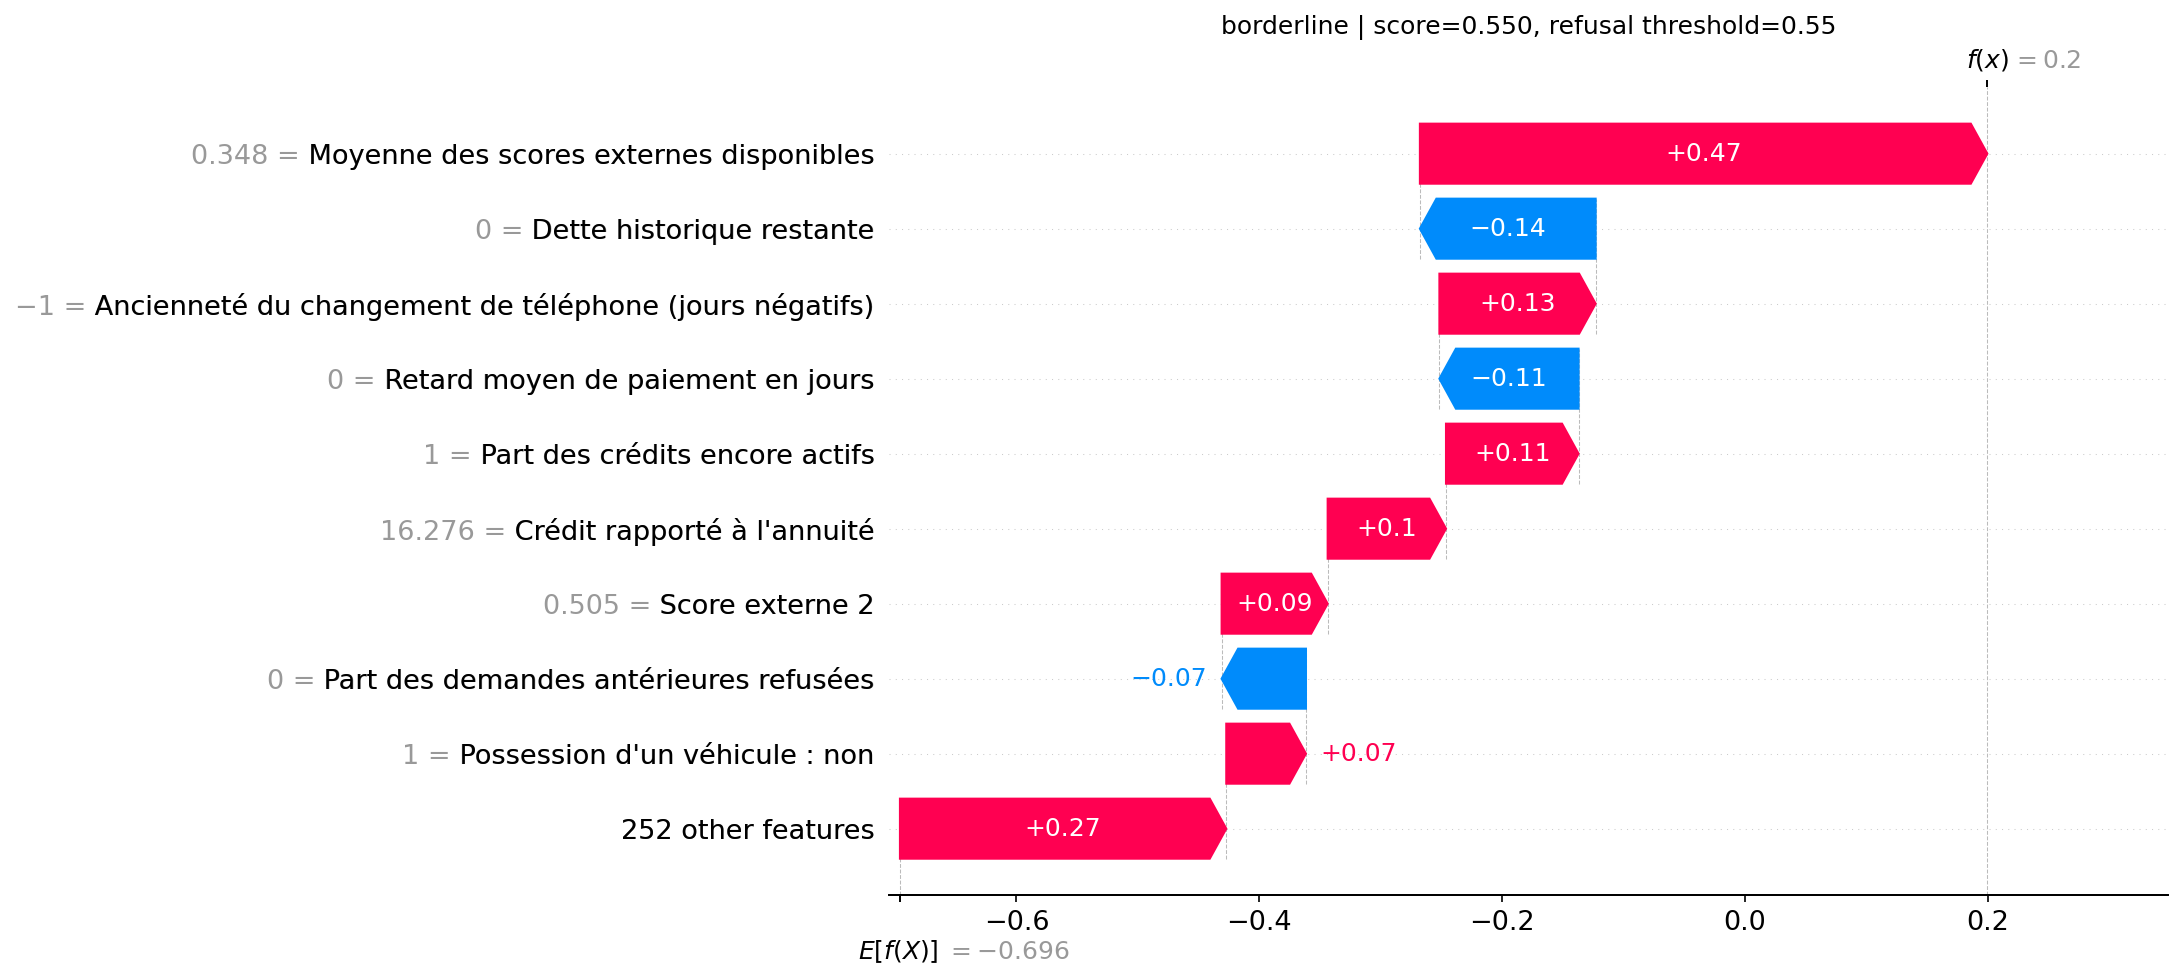